# 02 — Fault diagnosis: Mamba2 vs XGBoost vs KAN vs 1-D CNN
**Thesis:** Energy-Efficient and Fault-Tolerant IM Drive (IFOC vs DTC) — Section 5.5 of the proposal (RQ5).

**Data:** `dataset/fault_windows.mat` from section 8 of `main_run_all` —
`X` [n × 200 × 6] windows (20 ms at 10 kHz), `y` class 0 healthy / 1 speed sensor / 2 current sensor / 3 open phase.

**Models**
* **Mamba2** [32] on the raw window as a sequence. Uses the official `mamba_ssm.Mamba2` kernel if it is installed
  *and* an NVIDIA GPU is present (e.g. Google Colab); otherwise a pure-PyTorch implementation of the same Mamba-2
  (SSD) recurrence is used, so the notebook runs on any PC.
* **XGBoost** [29] and **KAN** [30] on hand-crafted features per window (RMS, mean, std, peak, current imbalance,
  third-difference values as in [14], …).
* **1-D CNN** on the raw window — simple deep-learning baseline.

**Evaluation:** accuracy, macro-F1, confusion matrix, inference time, robustness to added measurement noise,
and (if speed/load metadata are in the file) generalization to speed–load points left out of training.

Put this notebook in `Electrical Drive/python` and run all cells.

In [17]:
# ---------------- CONFIG ----------------
from pathlib import Path
ROOT     = Path('..')                         # the "Electrical Drive" folder
DATA     = ROOT / 'dataset' / 'fault_windows.mat'
OUT      = ROOT / 'python_out'
SEED     = 0
CLASSES  = ['healthy', 'speed sensor', 'current sensor', 'open phase']
CH_NAMES = None          # e.g. ['ia','ib','ic','w_m','Te_est','w_ref']; None = read from file or ch0..ch5
CURRENT_CH = [0, 1, 2]   # which channels are the three phase currents (for the imbalance features)
N_RUNS   = 576           # Simulink runs in the dataset (proposal 5.5); used to keep windows of one run together
EPOCHS   = 40            # deep models (CNN, Mamba2)
BATCH    = 64
NOISE_LEVELS = [0.01, 0.05]   # added Gaussian noise, as a fraction of each channel's std
AUGMENT_NOISE = True         # True = also train on noisy copies of the training windows (1 % and 5 %)
TAG = '_aug' if AUGMENT_NOISE else ''      # output files get this suffix, so both runs are kept
OUT.mkdir(exist_ok=True)

In [18]:
import time, json, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.io import loadmat
from sklearn.model_selection import StratifiedKFold, GroupShuffleSplit, GroupKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay, classification_report
import torch, torch.nn as nn, torch.nn.functional as F
warnings.filterwarnings('ignore')
try:
    from xgboost import XGBClassifier
    HAS_XGB = True
except ImportError:
    HAS_XGB = False; print('xgboost missing -> pip install xgboost')
DEV = 'cuda' if torch.cuda.is_available() else 'cpu'
try:
    from mamba_ssm import Mamba2 as Mamba2Official
    HAS_MAMBA_SSM = DEV == 'cuda'
except Exception:
    HAS_MAMBA_SSM = False
np.random.seed(SEED); torch.manual_seed(SEED)
plt.rcParams.update({'figure.dpi': 110})
print(f'torch {torch.__version__} | device {DEV} | official mamba_ssm kernel: {HAS_MAMBA_SSM}')

torch 2.14.1+cpu | device cpu | official mamba_ssm kernel: False


## 1. Load the dataset
Works for both normal `.mat` files and `-v7.3` (HDF5) files. All variables found in the file are listed;
vectors with one value per window (e.g. drive type, speed, load, run number) are kept as metadata.

In [19]:
def load_mat(path):
    try:
        d = loadmat(path, squeeze_me=True)
        return {k: v for k, v in d.items() if not k.startswith('__')}, False
    except Exception:
        import h5py                                    # MATLAB -v7.3
        out = {}
        with h5py.File(path, 'r') as f:
            for k in f.keys():
                if isinstance(f[k], h5py.Dataset):
                    a = np.array(f[k])
                    out[k] = a.T if a.ndim > 1 else a      # HDF5 stores MATLAB arrays transposed
        return out, True

raw, v73 = load_mat(DATA)
print(f'{DATA.name}  (v7.3: {v73})')
for k, v in raw.items():
    print(f'  {k:12s} {type(v).__name__:10s} {getattr(v, "shape", "")} {getattr(v, "dtype", "")}')

X = np.asarray(raw['X'], dtype=np.float32)
y = np.asarray(raw['y']).astype(int).ravel()
if X.ndim != 3:
    raise ValueError(f'X should be 3-D [n x 200 x channels], got {X.shape}')
if X.shape[0] != len(y):                           # try other orientations
    for perm in [(2, 1, 0), (2, 0, 1), (0, 2, 1), (1, 0, 2), (1, 2, 0)]:
        if X.transpose(perm).shape[0] == len(y):
            X = X.transpose(perm); break
n, L, C = X.shape
if L < C:                                          # [n, C, L] -> [n, L, C]
    X = X.transpose(0, 2, 1); n, L, C = X.shape
meta = {k: np.asarray(v).ravel() for k, v in raw.items()
        if k not in ('X', 'y') and np.size(v) == n and np.asarray(v).dtype.kind in 'iuf'}
if CH_NAMES is None:
    CH_NAMES = [f'ch{i}' for i in range(C)]
    for k, v in raw.items():
        if 'name' in k.lower() and np.size(v) == C:
            CH_NAMES = [str(s).strip() for s in np.ravel(v)]
print(f'\nX: {n} windows x {L} samples x {C} channels   channels: {CH_NAMES}')
print('class counts:', dict(zip(CLASSES, np.bincount(y, minlength=4))))
print('metadata vectors found:', list(meta))
if not np.isfinite(X).all():
    print('WARNING: non-finite values found -> replaced by 0'); X = np.nan_to_num(X)

fault_windows.mat  (v7.3: False)
  X            ndarray    (2880, 200, 6) float32
  y            ndarray    (2880,) uint8
  meta         ndarray    (2880, 6) float64
  channels     ndarray    (6,) object
  labels       ndarray    (4,) object
  meta_cols    ndarray    (6,) object

X: 2880 windows x 200 samples x 6 channels   channels: ['ch0', 'ch1', 'ch2', 'ch3', 'ch4', 'ch5']
class counts: {'healthy': np.int64(1584), 'speed sensor': np.int64(432), 'current sensor': np.int64(432), 'open phase': np.int64(432)}
metadata vectors found: []


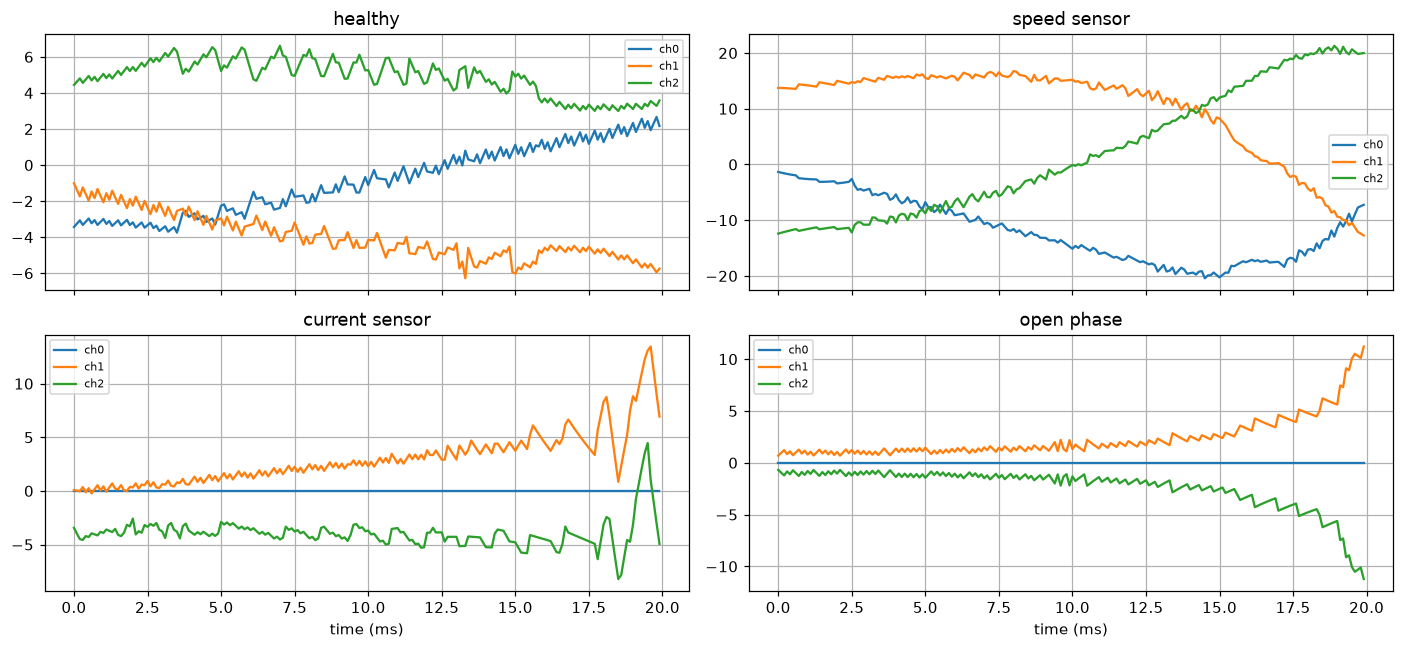

In [20]:
# One example window per class
fig, ax = plt.subplots(2, 2, figsize=(13, 6), sharex=True)
t_ms = np.arange(L) / 10.0
for c, a in enumerate(ax.ravel()):
    i = np.where(y == c)[0][len(np.where(y == c)[0]) // 2]
    for ch in range(min(C, 3)):
        a.plot(t_ms, X[i, :, ch], label=CH_NAMES[ch])
    a.set_title(CLASSES[c]); a.legend(fontsize=7); a.grid(True)
ax[1, 0].set_xlabel('time (ms)'); ax[1, 1].set_xlabel('time (ms)')
plt.tight_layout(); plt.savefig(OUT / 'fig_fault_examples.png', dpi=200); plt.show()

## 2. Train / validation / test split (70 / 15 / 15)
Windows cut from the **same Simulink run** look alike, so they are kept in the same split (group split);
otherwise test accuracy would be optimistic. The run number comes from a `run` metadata vector if present,
otherwise windows are assumed to be stored run by run (`n / N_RUNS` consecutive windows per run).

In [21]:
run_key = next((k for k in meta if k.lower() in ('run', 'run_id', 'irun', 'sim', 'sim_id')), None)
if run_key:
    groups = meta[run_key].astype(int); print('groups from metadata vector', run_key)
elif n % N_RUNS == 0:
    groups = np.arange(n) // (n // N_RUNS); print(f'groups: {n // N_RUNS} consecutive windows per run (assumed)')
else:
    groups = np.arange(n); print('WARNING: run grouping unknown -> plain split (may be optimistic)')

gss = GroupShuffleSplit(1, test_size=0.30, random_state=SEED)
tr, tmp = next(gss.split(X, y, groups))
gss2 = GroupShuffleSplit(1, test_size=0.50, random_state=SEED)
va_i, te_i = next(gss2.split(X[tmp], y[tmp], groups[tmp]))
va, te = tmp[va_i], tmp[te_i]
print(f'train {len(tr)}  val {len(va)}  test {len(te)}')
for nm, idx in [('train', tr), ('val', va), ('test', te)]:
    print(f'  {nm:5s} class counts {np.bincount(y[idx], minlength=4)}')

# per-channel normalization (train statistics only)
ch_mu = X[tr].mean(axis=(0, 1));  ch_sd = X[tr].std(axis=(0, 1)) + 1e-6
Xn = (X - ch_mu) / ch_sd

def add_noise(Xw, frac, seed=1):
    rng = np.random.default_rng(seed)
    return Xw + rng.normal(0, 1, Xw.shape).astype(np.float32) * (frac * ch_sd)

groups: 5 consecutive windows per run (assumed)
train 2015  val 430  test 435
  train class counts [1115  306  309  285]
  val   class counts [232  54  69  75]
  test  class counts [237  72  54  72]


## 3. Hand-crafted features (for XGBoost and KAN)
Per channel: mean, std, RMS, min, max, peak-to-peak, mean |1st difference|, max |3rd difference| (the operator of [14]).
Currents: RMS of each phase relative to their mean (imbalance), |ia+ib+ic| (KCL residual), min-RMS/max-RMS ratio.

In [22]:
def features(Xw):
    f, names = [], []
    d1 = np.diff(Xw, 1, axis=1);  d3 = np.diff(Xw, 3, axis=1)
    stats = {'mean': Xw.mean(1), 'std': Xw.std(1), 'rms': np.sqrt((Xw**2).mean(1)), 'min': Xw.min(1),
             'max': Xw.max(1), 'ptp': np.ptp(Xw, 1), 'd1': np.abs(d1).mean(1), 'd3max': np.abs(d3).max(1)}
    for s, v in stats.items():
        f.append(v); names += [f'{s}_{CH_NAMES[c]}' for c in range(Xw.shape[2])]
    if len(CURRENT_CH) == 3 and max(CURRENT_CH) < Xw.shape[2]:
        I = Xw[:, :, CURRENT_CH];  rms = np.sqrt((I**2).mean(1)) + 1e-9
        f += [rms / rms.mean(1, keepdims=True), (rms.min(1) / rms.max(1))[:, None],
              np.abs(I.sum(2)).mean(1)[:, None]]
        names += [f'imb_{CH_NAMES[c]}' for c in CURRENT_CH] + ['rms_ratio', 'kcl_residual']
    return np.concatenate(f, 1).astype(np.float32), names

Fe, feat_names = features(X)
print(f'{Fe.shape[1]} features per window')
sc = StandardScaler().fit(Fe[tr])
Fs = np.clip(sc.transform(Fe), -5, 5).astype(np.float32)

def feats_of(Xraw):
    return np.clip(sc.transform(features(Xraw)[0]), -5, 5).astype(np.float32)

# ---- training set: clean windows, plus noisy copies if AUGMENT_NOISE ----
# (noise seeds 100+ differ from the seed used later for the noisy TEST windows)
if AUGMENT_NOISE:
    X_tr_raw = np.concatenate([X[tr]] + [add_noise(X[tr], f, seed=100 + k) for k, f in enumerate(NOISE_LEVELS)])
    reps = 1 + len(NOISE_LEVELS)
else:
    X_tr_raw, reps = X[tr], 1
y_tr = np.tile(y[tr], reps);  g_tr = np.tile(groups[tr], reps)
Xn_tr = (X_tr_raw - ch_mu) / ch_sd
F_tr = feats_of(X_tr_raw)
print(f'training windows: {len(y_tr)}  (noise augmentation: {AUGMENT_NOISE})')

53 features per window
training windows: 6045  (noise augmentation: True)


## 4. Models

In [23]:
# ---------- KAN (efficient-KAN formulation, cubic B-splines) ----------
class KANLinear(nn.Module):
    def __init__(self, nin, nout, G=5, k=3, lo=-1.0, hi=1.0):
        super().__init__()
        h = (hi - lo) / G
        self.register_buffer('grid', torch.arange(-k, G + k + 1, dtype=torch.float32) * h + lo)
        self.k, self.lo, self.hi = k, lo, hi
        self.base = nn.Linear(nin, nout)
        self.coef = nn.Parameter(0.1 * torch.randn(nout, nin, G + k))
    def bsplines(self, x):
        g = self.grid;  x = x.clamp(self.lo, self.hi - 1e-6).unsqueeze(-1)
        B = ((x >= g[:-1]) & (x < g[1:])).to(x.dtype)
        for p in range(1, self.k + 1):
            B = (x - g[:-(p + 1)]) / (g[p:-1] - g[:-(p + 1)]) * B[..., :-1] + \
                (g[p + 1:] - x) / (g[p + 1:] - g[1:-p]) * B[..., 1:]
        return B
    def forward(self, x):
        return self.base(F.silu(x)) + torch.einsum('bik,oik->bo', self.bsplines(x), self.coef)

class KANClassifier(nn.Module):
    def __init__(self, nin, hidden=16, ncls=4, G=5):
        super().__init__()
        self.l1 = KANLinear(nin, hidden, G, lo=-5, hi=5)
        self.l2 = KANLinear(hidden, ncls, G, lo=-3, hi=3)
    def forward(self, x):
        return self.l2(self.l1(x))

# ---------- 1-D CNN baseline ----------
class CNN1D(nn.Module):
    def __init__(self, C, ncls=4):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv1d(C, 32, 7, padding=3), nn.BatchNorm1d(32), nn.ReLU(), nn.MaxPool1d(2),
            nn.Conv1d(32, 64, 5, padding=2), nn.BatchNorm1d(64), nn.ReLU(), nn.MaxPool1d(2),
            nn.Conv1d(64, 64, 3, padding=1), nn.BatchNorm1d(64), nn.ReLU(), nn.AdaptiveAvgPool1d(1))
        self.fc = nn.Linear(64, ncls)
    def forward(self, x):                      # x [B, L, C]
        return self.fc(self.net(x.transpose(1, 2)).squeeze(-1))

# ---------- Mamba-2 ----------
class Mamba2Ref(nn.Module):
    """Pure-PyTorch Mamba-2 (SSD) block, sequential scan.
    h_t = exp(dt_t*A_h) h_{t-1} + dt_t * x_t B_t^T,  y_t = h_t C_t + D_h x_t   (scalar A per head),
    with the Mamba-2 input projection (z, x, B, C, dt), causal depthwise conv and gated output."""
    def __init__(self, d_model, d_state=16, headdim=16, expand=2, d_conv=4):
        super().__init__()
        self.d_inner = expand * d_model;  self.N = d_state;  self.P = headdim;  self.H = self.d_inner // headdim
        conv_dim = self.d_inner + 2 * d_state
        self.in_proj = nn.Linear(d_model, 2 * self.d_inner + 2 * d_state + self.H)
        self.conv = nn.Conv1d(conv_dim, conv_dim, d_conv, groups=conv_dim, padding=d_conv - 1)
        self.A_log = nn.Parameter(torch.log(torch.linspace(1, 16, self.H)))
        dt = torch.exp(torch.rand(self.H) * (np.log(0.1) - np.log(0.001)) + np.log(0.001))
        self.dt_bias = nn.Parameter(dt + torch.log(-torch.expm1(-dt)))      # inverse softplus
        self.D = nn.Parameter(torch.ones(self.H))
        self.norm = nn.LayerNorm(self.d_inner)
        self.out_proj = nn.Linear(self.d_inner, d_model)
    def forward(self, u):                                   # u [B, L, d_model]
        Bsz, Lq, _ = u.shape
        z, xBC, dt = torch.split(self.in_proj(u), [self.d_inner, self.d_inner + 2 * self.N, self.H], -1)
        xBC = F.silu(self.conv(xBC.transpose(1, 2))[..., :Lq].transpose(1, 2))
        x, Bm, Cm = torch.split(xBC, [self.d_inner, self.N, self.N], -1)
        dt = F.softplus(dt + self.dt_bias)                  # [B, L, H]
        dA = torch.exp(dt * (-torch.exp(self.A_log)))       # [B, L, H]
        x = x.view(Bsz, Lq, self.H, self.P)
        h = u.new_zeros(Bsz, self.H, self.P, self.N);  ys = []
        for t in range(Lq):
            h = h * dA[:, t, :, None, None] + (dt[:, t, :, None, None] * x[:, t, :, :, None]) * Bm[:, t, None, None, :]
            ys.append((h * Cm[:, t, None, None, :]).sum(-1) + self.D[None, :, None] * x[:, t])
        y_ = torch.stack(ys, 1).reshape(Bsz, Lq, self.d_inner)
        return self.out_proj(self.norm(y_) * F.silu(z))

class MambaClassifier(nn.Module):
    def __init__(self, C, d_model=32, n_layers=2, ncls=4, downsample=2):
        super().__init__()
        self.ds = downsample
        self.inp = nn.Linear(C, d_model)
        if HAS_MAMBA_SSM:
            mk = lambda: Mamba2Official(d_model=d_model, d_state=16, d_conv=4, expand=2, headdim=16)
        else:
            mk = lambda: Mamba2Ref(d_model, d_state=16, headdim=16, expand=2)
        self.blocks = nn.ModuleList([mk() for _ in range(n_layers)])
        self.norms = nn.ModuleList([nn.LayerNorm(d_model) for _ in range(n_layers)])
        self.fc = nn.Linear(d_model, ncls)
    def forward(self, x):                                   # x [B, L, C]
        if self.ds > 1:
            x = F.avg_pool1d(x.transpose(1, 2), self.ds).transpose(1, 2)
        h = self.inp(x)
        for blk, nrm in zip(self.blocks, self.norms):
            h = h + blk(nrm(h))
        return self.fc(h.mean(1))

# ---------- generic training loop (early stopping on validation macro-F1) ----------
def train_torch(model, Xtr, ytr, Xva, yva, epochs=EPOCHS, lr=2e-3, wd=1e-4, batch=BATCH, name=''):
    model = model.to(DEV)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, epochs)
    w = torch.tensor(len(ytr) / (4 * np.bincount(ytr, minlength=4) + 1e-9), dtype=torch.float32, device=DEV)
    Xt, yt = torch.tensor(Xtr), torch.tensor(ytr)
    best, best_state = (-1, -np.inf), None
    hist = {'train_loss': [], 'val_loss': [], 'val_f1': [], 'best_epoch': 0}
    for ep in range(epochs):
        model.train();  perm = torch.randperm(len(Xt));  tl, nb = 0.0, 0
        for i in range(0, len(Xt), batch):
            b = perm[i:i + batch]
            loss = F.cross_entropy(model(Xt[b].to(DEV)), yt[b].to(DEV), weight=w)
            opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
            tl += loss.item();  nb += 1
        sched.step()
        vl, yp = eval_torch(model, Xva, yva, w)
        f1 = f1_score(yva, yp, average='macro')
        hist['train_loss'].append(tl / nb);  hist['val_loss'].append(vl);  hist['val_f1'].append(f1)
        # early stopping: best validation macro-F1, ties broken by lower validation loss
        if (f1, -vl) > best:
            best, best_state, hist['best_epoch'] = (f1, -vl), {k: v.detach().clone() for k, v in model.state_dict().items()}, ep
        if ep % 5 == 0 or ep == epochs - 1:
            print(f'  {name} epoch {ep:3d}  train loss {tl/nb:.4f}  val loss {vl:.4f}  val macro-F1 {f1:.4f}')
    model.load_state_dict(best_state);  return model, hist

@torch.no_grad()
def eval_torch(model, Xw, yw, w=None, batch=256):
    model.eval();  L_, P_ = 0.0, []
    for i in range(0, len(Xw), batch):
        out = model(torch.tensor(Xw[i:i + batch]).to(DEV));  yb = torch.tensor(yw[i:i + batch]).to(DEV)
        L_ += F.cross_entropy(out, yb, weight=w, reduction='sum').item();  P_.append(out.argmax(1).cpu().numpy())
    return L_ / len(Xw), np.concatenate(P_)

@torch.no_grad()
def predict_torch(model, Xw, batch=256):
    model.eval();  out = []
    for i in range(0, len(Xw), batch):
        out.append(model(torch.tensor(Xw[i:i + batch]).to(DEV)).argmax(1).cpu().numpy())
    return np.concatenate(out)

## 5. Train all four models

In [24]:
models, preds, hists, info = {}, {}, {}, {}

# --- XGBoost on features (5-fold CV over a small grid) ---
if HAS_XGB:
    t0 = time.time()
    gs = GridSearchCV(XGBClassifier(random_state=SEED, n_jobs=4, verbosity=0, eval_metric='mlogloss'),
                      {'n_estimators': [200, 500], 'max_depth': [3, 5], 'learning_rate': [0.05, 0.2]},
                      cv=GroupKFold(5), scoring='f1_macro', n_jobs=1)
    gs.fit(F_tr, y_tr, groups=g_tr)     # GroupKFold: windows of one run stay in one fold
    models['XGBoost'] = gs.best_estimator_
    info['XGBoost'] = dict(train_s=time.time() - t0, params=int(sum(len(t.splitlines()) for t in gs.best_estimator_.get_booster().get_dump())),
                           hparams=json.dumps(gs.best_params_), input='features')
    print('XGBoost best', gs.best_params_, f'({info["XGBoost"]["train_s"]:.0f} s)')

# --- KAN on features ---
torch.manual_seed(SEED);  t0 = time.time()
kan = KANClassifier(Fs.shape[1], hidden=16)
models['KAN'], hists['KAN'] = train_torch(kan, F_tr, y_tr, Fs[va], y[va], epochs=150, lr=3e-3, batch=128, name='KAN')
info['KAN'] = dict(train_s=time.time() - t0, params=sum(p.numel() for p in kan.parameters()), hparams='hidden=16,G=5', input='features')

# --- 1-D CNN on raw windows ---
torch.manual_seed(SEED);  t0 = time.time()
cnn = CNN1D(C)
models['1-D CNN'], hists['1-D CNN'] = train_torch(cnn, Xn_tr, y_tr, Xn[va], y[va], name='CNN')
info['1-D CNN'] = dict(train_s=time.time() - t0, params=sum(p.numel() for p in cnn.parameters()), hparams='3 conv layers', input='raw')

# --- Mamba2 on raw windows ---
torch.manual_seed(SEED);  t0 = time.time()
mam = MambaClassifier(C)
models['Mamba2'], hists['Mamba2'] = train_torch(mam, Xn_tr, y_tr, Xn[va], y[va], lr=2e-3, name='Mamba2')
info['Mamba2'] = dict(train_s=time.time() - t0, params=sum(p.numel() for p in mam.parameters()),
                      hparams=f'd_model=32, 2 layers, d_state=16, {"mamba_ssm kernel" if HAS_MAMBA_SSM else "PyTorch reference scan"}',
                      input='raw')

XGBoost best {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 500} (26 s)
  KAN epoch   0  train loss 0.4475  val loss 0.1362  val macro-F1 0.9641
  KAN epoch   5  train loss 0.0136  val loss 0.0362  val macro-F1 0.9860
  KAN epoch  10  train loss 0.0040  val loss 0.0636  val macro-F1 0.9825
  KAN epoch  15  train loss 0.0026  val loss 0.0413  val macro-F1 0.9860
  KAN epoch  20  train loss 0.0008  val loss 0.0411  val macro-F1 0.9895
  KAN epoch  25  train loss 0.0005  val loss 0.0436  val macro-F1 0.9860
  KAN epoch  30  train loss 0.0003  val loss 0.0455  val macro-F1 0.9895
  KAN epoch  35  train loss 0.0003  val loss 0.0506  val macro-F1 0.9860
  KAN epoch  40  train loss 0.0002  val loss 0.0409  val macro-F1 0.9930
  KAN epoch  45  train loss 0.0001  val loss 0.0508  val macro-F1 0.9860
  KAN epoch  50  train loss 0.0012  val loss 0.0617  val macro-F1 0.9860
  KAN epoch  55  train loss 0.0001  val loss 0.0488  val macro-F1 0.9930
  KAN epoch  60  train loss 0.0001  val los

## 6. Test-set results

  model    input  accuracy  macro_F1  params  infer_ms_per_window  train_s
XGBoost features    1.0000    1.0000    6472               0.0380  26.3535
    KAN features    1.0000    1.0000    8228               0.0223  41.4870
 Mamba2      raw    1.0000    1.0000   16708               0.5254 843.2497
1-D CNN      raw    0.9954    0.9925   24612               0.0488  35.8982


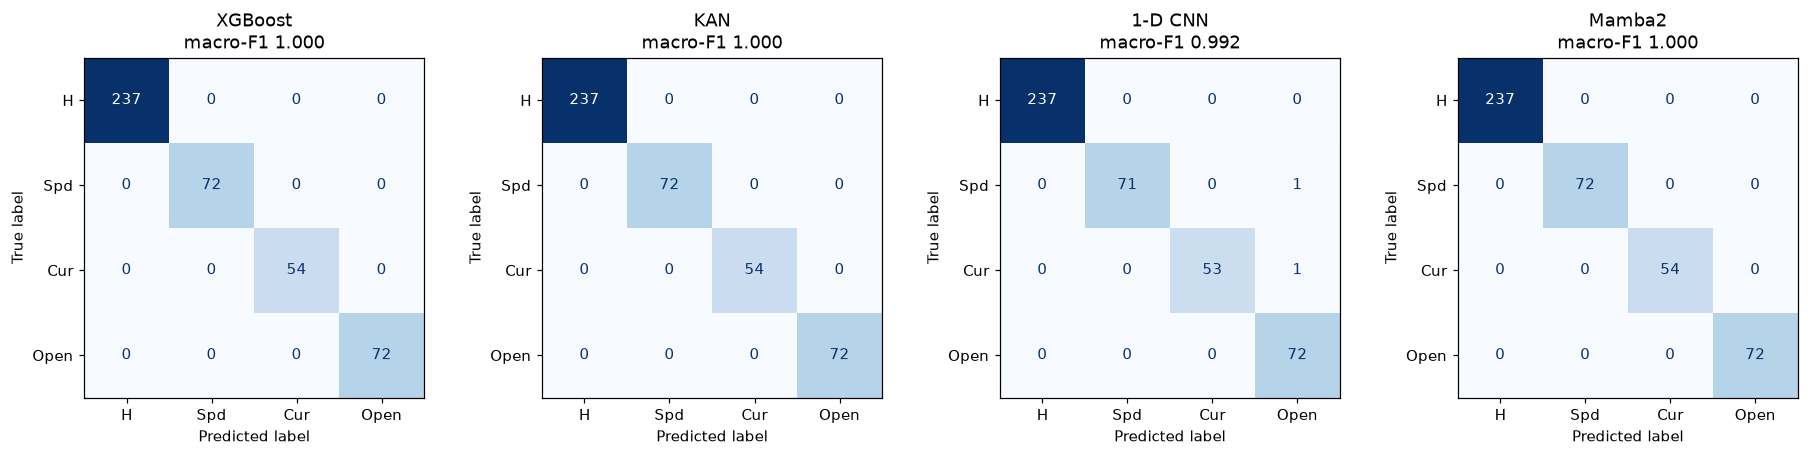


===== XGBoost =====
                precision    recall  f1-score   support

       healthy      1.000     1.000     1.000       237
  speed sensor      1.000     1.000     1.000        72
current sensor      1.000     1.000     1.000        54
    open phase      1.000     1.000     1.000        72

      accuracy                          1.000       435
     macro avg      1.000     1.000     1.000       435
  weighted avg      1.000     1.000     1.000       435


===== KAN =====
                precision    recall  f1-score   support

       healthy      1.000     1.000     1.000       237
  speed sensor      1.000     1.000     1.000        72
current sensor      1.000     1.000     1.000        54
    open phase      1.000     1.000     1.000        72

      accuracy                          1.000       435
     macro avg      1.000     1.000     1.000       435
  weighted avg      1.000     1.000     1.000       435


===== 1-D CNN =====
                precision    recall  f1

In [25]:
def model_predict(name, Xraw_norm, Ffeat):
    m = models[name]
    if name == 'XGBoost':
        return m.predict(Ffeat)
    return predict_torch(m, Ffeat if info[name]['input'] == 'features' else Xraw_norm)

rows = []
for name in models:
    t0 = time.perf_counter();  yp = model_predict(name, Xn[te], Fs[te]);  dt = time.perf_counter() - t0
    preds[name] = yp
    rows.append(dict(model=name, input=info[name]['input'], accuracy=accuracy_score(y[te], yp),
                     macro_F1=f1_score(y[te], yp, average='macro'), params=info[name]['params'],
                     infer_ms_per_window=1e3 * dt / len(te), train_s=info[name]['train_s'], hparams=info[name]['hparams']))
res = pd.DataFrame(rows).sort_values('macro_F1', ascending=False)
res.to_csv(OUT / f'fault_model_comparison{TAG}.csv', index=False)
print(res.drop(columns='hparams').round(4).to_string(index=False))

fig, ax = plt.subplots(1, len(models), figsize=(4.2 * len(models), 4))
for a, name in zip(np.atleast_1d(ax), models):
    ConfusionMatrixDisplay(confusion_matrix(y[te], preds[name], labels=range(4)),
                           display_labels=['H', 'Spd', 'Cur', 'Open']).plot(ax=a, colorbar=False, cmap='Blues')
    a.set_title(f'{name}\nmacro-F1 {f1_score(y[te], preds[name], average="macro"):.3f}')
plt.tight_layout(); plt.savefig(OUT / f'fig_fault_confusion{TAG}.png', dpi=200); plt.show()

for name in models:
    print(f'\n===== {name} =====')
    print(classification_report(y[te], preds[name], labels=range(4), target_names=CLASSES, digits=3, zero_division=0))

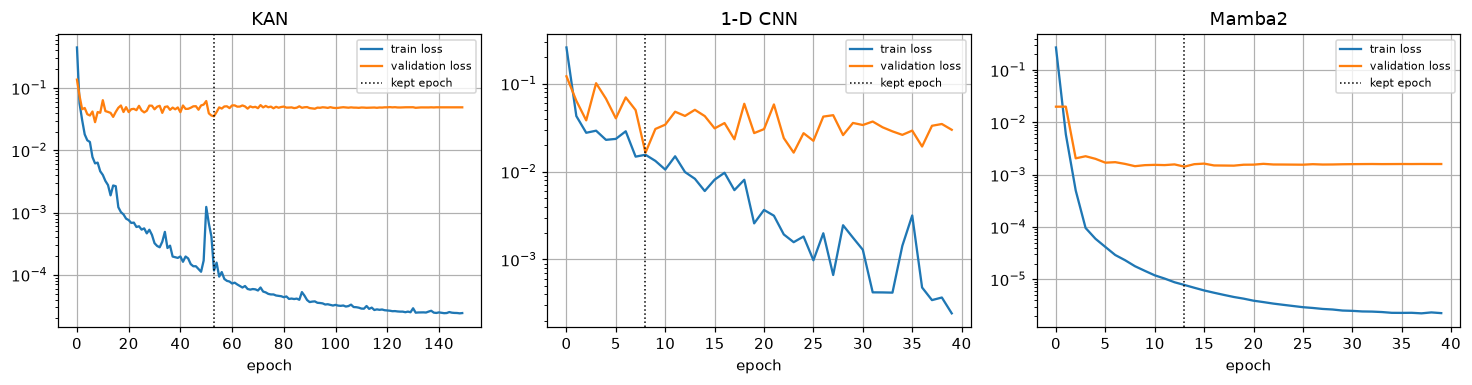

In [26]:
# Learning curves (validation macro-F1 per epoch)
fig, ax = plt.subplots(1, len(hists), figsize=(4.5 * len(hists), 3.6), squeeze=False)
for a, (name, h) in zip(ax[0], hists.items()):
    a.plot(h['train_loss'], label='train loss');  a.plot(h['val_loss'], label='validation loss')
    a.axvline(h['best_epoch'], color='k', ls=':', lw=1, label='kept epoch')
    a.set_yscale('log');  a.set_xlabel('epoch');  a.set_title(name);  a.legend(fontsize=7);  a.grid(True)
plt.tight_layout(); plt.savefig(OUT / f'fig_fault_loss_curves{TAG}.png', dpi=200); plt.show()

## 6b. Over-fitting / under-fitting check
Macro-F1 on the **training** windows (clean), the **validation** windows (used only for early stopping /
model selection) and the **test** windows (never used). Rules, fixed in advance:
* **Under-fit** — training macro-F1 < 0.95: the model cannot even separate the classes it was trained on.
* **Over-fit** — training macro-F1 − validation or test macro-F1 > 0.03: it does much better on data it has seen.
* Otherwise **good fit**. The loss curves above should show the validation loss following the training loss;
  a validation loss that rises while the training loss keeps falling is over-fitting, and the dotted line marks
  the epoch that was kept (early stopping), so later over-fitting does not reach the final model.
* XGBoost also reports its 5-fold **grouped** cross-validation score.

A test score of ~1.0 for every model with a good-fit verdict is possible here: simulated faults are very
distinct. The noise test in Section 8 is what separates the models.

In [27]:
fit_rows = []
for name in models:
    f_tr = f1_score(y[tr], model_predict(name, Xn[tr], Fs[tr]), average='macro')
    f_va = f1_score(y[va], model_predict(name, Xn[va], Fs[va]), average='macro')
    f_te = f1_score(y[te], preds[name], average='macro')
    gap = max(f_tr - f_va, f_tr - f_te)
    v = 'UNDER-FIT' if f_tr < 0.95 else ('OVER-FIT' if gap > 0.03 else 'good fit')
    row = dict(model=name, train_F1=f_tr, val_F1=f_va, test_F1=f_te, max_gap=gap, fit=v)
    if name == 'XGBoost':
        row['cv_F1'] = gs.best_score_
    if name in hists:
        row['kept_epoch'] = hists[name]['best_epoch']
        row['final_train_loss'] = hists[name]['train_loss'][-1];  row['final_val_loss'] = hists[name]['val_loss'][-1]
    fit_rows.append(row)
fitdiag = pd.DataFrame(fit_rows)
fitdiag.to_csv(OUT / f'table_fault_fit_check{TAG}.csv', index=False)
print(fitdiag.round(4).to_string(index=False))

  model  train_F1  val_F1  test_F1  max_gap      fit  cv_F1  kept_epoch  final_train_loss  final_val_loss
XGBoost    1.0000  0.9965   1.0000   0.0035 good fit 0.9987         NaN               NaN             NaN
    KAN    1.0000  0.9965   1.0000   0.0035 good fit    NaN        53.0            0.0000          0.0489
1-D CNN    0.9992  0.9965   0.9925   0.0067 good fit    NaN         8.0            0.0002          0.0299
 Mamba2    1.0000  1.0000   1.0000   0.0000 good fit    NaN        13.0            0.0000          0.0016


## 7. Results per drive (IFOC vs DTC)
Only if the file has a drive / control-type vector (e.g. `drive`, `ctrl`, `type`).

In [28]:
drv_key = next((k for k in meta if k.lower() in ('drive', 'ctrl', 'ctrl_type', 'type', 'drive_type')), None)
if drv_key:
    dv = meta[drv_key][te]
    tab = []
    for name in models:
        for val in np.unique(dv):
            m = dv == val
            tab.append(dict(model=name, drive={1: 'IFOC', 2: 'DTC'}.get(int(val), str(val)),
                            accuracy=accuracy_score(y[te][m], preds[name][m]), macro_F1=f1_score(y[te][m], preds[name][m], average='macro')))
    print(pd.DataFrame(tab).pivot(index='model', columns='drive', values='macro_F1').round(4))
else:
    print('No drive metadata in the file -> per-drive table skipped')

No drive metadata in the file -> per-drive table skipped


## 8. Robustness to measurement noise
Gaussian noise (1 % and 5 % of each channel's standard deviation) is added to the **test** windows only.

In [29]:
rob = []
for frac in [0.0] + NOISE_LEVELS:
    Xte = X[te] if frac == 0 else add_noise(X[te], frac)
    Xte_n = (Xte - ch_mu) / ch_sd;  Fte = feats_of(Xte)
    for name in models:
        rob.append(dict(model=name, noise=f'{100*frac:.0f} %', macro_F1=f1_score(y[te], model_predict(name, Xte_n, Fte), average='macro')))
rob = pd.DataFrame(rob).pivot(index='model', columns='noise', values='macro_F1')
rob.to_csv(OUT / f'fault_noise_robustness{TAG}.csv');  print(rob.round(4))

noise       0 %     1 %     5 %
model                          
1-D CNN  0.9925  0.9925  0.9925
KAN      1.0000  0.9959  0.9959
Mamba2   1.0000  1.0000  1.0000
XGBoost  1.0000  1.0000  1.0000


## 9. Generalization to unseen speed–load points
Only if the file has speed and load vectors: models are retrained (XGBoost and CNN — the fast ones; set
`GEN_ALL = True` for all four) without the highest speed and lowest load levels, and tested on those points.

In [30]:
GEN_ALL = False
spd_key = next((k for k in meta if k.lower() in ('speed', 'w', 'w_ref', 'spd', 'n_ref')), None)
lod_key = next((k for k in meta if k.lower() in ('load', 't', 'tl', 't_load', 'torque')), None)
if spd_key and lod_key:
    s, l = meta[spd_key], meta[lod_key]
    held = (s == np.max(s)) | (l == np.min(l))
    gtr = np.where(~held)[0];  gte = np.where(held)[0]
    print(f'held-out windows: {len(gte)}  (speed = {np.max(s):g} or load = {np.min(l):g})')
    gen = []
    if HAS_XGB:
        m = XGBClassifier(**models['XGBoost'].get_params()).fit(Fs[gtr], y[gtr])
        gen.append(dict(model='XGBoost', macro_F1=f1_score(y[gte], m.predict(Fs[gte]), average='macro')))
    names = ['1-D CNN'] + (['KAN', 'Mamba2'] if GEN_ALL else [])
    for name in names:
        torch.manual_seed(SEED)
        mk = {'1-D CNN': lambda: CNN1D(C), 'KAN': lambda: KANClassifier(Fs.shape[1]), 'Mamba2': lambda: MambaClassifier(C)}[name]
        src = Fs if name == 'KAN' else Xn
        sub = np.random.default_rng(SEED).permutation(gtr);  cut = int(0.85 * len(sub))
        m, _ = train_torch(mk(), src[sub[:cut]], y[sub[:cut]], src[sub[cut:]], y[sub[cut:]], name=name + ' (gen)')
        gen.append(dict(model=name, macro_F1=f1_score(y[gte], predict_torch(m, src[gte]), average='macro')))
    gen = pd.DataFrame(gen);  gen.to_csv(OUT / f'fault_generalization{TAG}.csv', index=False);  print(gen.round(4))
else:
    print('No speed/load metadata in the file -> generalization test skipped.')
    print('Tip: save speed, load (and run, drive) vectors with one value per window in fault_windows.mat.')

No speed/load metadata in the file -> generalization test skipped.
Tip: save speed, load (and run, drive) vectors with one value per window in fault_windows.mat.


## 10. Detection delay (optional)
Needs, per window, the window start time and the fault onset time of its run (metadata `t0` and `t_fault`, s).
The delay of a model = time from fault onset to the end of the first window of that run that it classifies
as faulty. Compare with the rule-based detector of [14] from section 7 of `main_run_all`.

In [31]:
t0_key = next((k for k in meta if k.lower() in ('t0', 't_start', 'twin', 't_win')), None)
tf_key = next((k for k in meta if k.lower() in ('t_fault', 'tfault', 'onset', 't_onset')), None)
if t0_key and tf_key:
    t0w, tfa = meta[t0_key], meta[tf_key];  WIN = L / 10000.0
    dl = []
    for name in models:
        yp_all = model_predict(name, Xn, Fs)
        d_ = []
        for g in np.unique(groups[te]):
            idx = np.where(groups == g)[0]
            if y[idx].max() == 0: continue
            hit = idx[(yp_all[idx] > 0) & (t0w[idx] + WIN >= tfa[idx])]
            if len(hit): d_.append(1e3 * (t0w[hit].min() + WIN - tfa[hit[0]]))
        dl.append(dict(model=name, mean_delay_ms=np.mean(d_) if d_ else np.nan, runs_detected=len(d_)))
    print(pd.DataFrame(dl).round(2))
else:
    print('No window-time / fault-onset metadata -> detection delay skipped.')

No window-time / fault-onset metadata -> detection delay skipped.


## 11. Summary table for the thesis (RQ5)

In [32]:
summary = res[['model', 'input', 'accuracy', 'macro_F1', 'params', 'infer_ms_per_window']].set_index('model')
summary = summary.join(fitdiag.set_index('model')[['train_F1', 'fit']])
summary = summary.join(rob.add_prefix('F1 noise '))
summary = summary.round(4);  summary.to_csv(OUT / f'table_fault_models{TAG}.csv')
print(summary.to_string())

            input  accuracy  macro_F1  params  infer_ms_per_window  train_F1       fit  F1 noise 0 %  F1 noise 1 %  F1 noise 5 %
model                                                                                                                           
XGBoost  features    1.0000    1.0000    6472               0.0380    1.0000  good fit        1.0000        1.0000        1.0000
KAN      features    1.0000    1.0000    8228               0.0223    1.0000  good fit        1.0000        0.9959        0.9959
Mamba2        raw    1.0000    1.0000   16708               0.5254    1.0000  good fit        1.0000        1.0000        1.0000
1-D CNN       raw    0.9954    0.9925   24612               0.0488    0.9992  good fit        0.9925        0.9925        0.9925
